# Training and Validation Data Objective

In [1]:
from torch import nn,optim
import torch
import numpy as np
import matplotlib.pyplot as plt

### Make some Data

In [2]:
# Create data class
from torch.utils.data import DataLoader,Dataset

class Data(Dataset):
    # Constructor
    def __init__(self,train = True):
        self.x = torch.arange(-3,3,0.1).view(-1,1)
        self.f = -3 * self.x + 1
        self.y = self.f + 0.1 * torch.randn(self.x.size())
        self.len = self.x.shape[0]
        # outliers
        if train == True:
            self.y[0] = 0
            self.y[50:55] = 20
        else:
            pass

     # Getter        
    def __getitem__(self, index):
        return self.x[index], self.y[index]

    # Get Lenght
    def __len__(self):
        return self.len
    
        

In [3]:
# Create training dataset and validation dataset

train_data = Data()
val_data = Data(train=False)

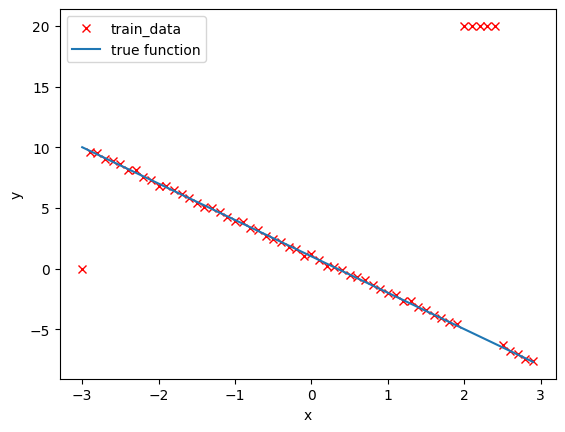

In [4]:
# Plot out training points
plt.plot(train_data.x.numpy(),train_data.y.numpy(),'xr',label='train_data')
plt.plot(train_data.x.numpy(),train_data.f.numpy(),label='true function')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

### Create a linear Regression object data loader and criterion function

In [5]:
# Create linear regression class

from torch import nn
class linear_reg(nn.Module):

    # Constructor
    def __init__(self, input_size, output_size):
        super(linear_reg,self).__init__()
        self.linear = nn.Linear(input_size,output_size)

    def forward(self,x):
        yhat = self.linear(x)
        return yhat

In [6]:
# Create MSELoss function and DataLoader
criterion = nn.MSELoss()
trainloader = DataLoader(dataset=train_data,batch_size=1)

### Different learning rate and Data Structure to store result for different Hyperparameters

In [8]:
# Create learning rate list, error liste and the models list
lr = [0.0001,0.001,0.01,0.1]
train_error = torch.zeros(len(lr))
validation_error = torch.zeros(len(lr))
MODELS = []

### Train diffrent modules for different Hyperparameters

In [9]:
def train_model_lr(iter,lr_list):
    # iterate through different lr
    for i, lr in enumerate(lr_list):
        model = linear_reg(1,1)
        optimizer = optim.SGD(model.parameters(), lr=lr)
        for epoch in range(iter):
            for x,y in trainloader:
                yhat = model(x)
                loss = criterion(yhat,y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        # train data
        Yhat = model(train_data.x)
        train_loss = criterion(Yhat, train_data.y)
        train_error[i] = train_loss.item()

        # validation data
        Yhat = model(val_data.x)
        val_loss = criterion(Yhat, val_data.y)
        validation_error[i] = val_loss.item()
        MODELS.append(model)

train_model_lr(10,lr)

### View Results

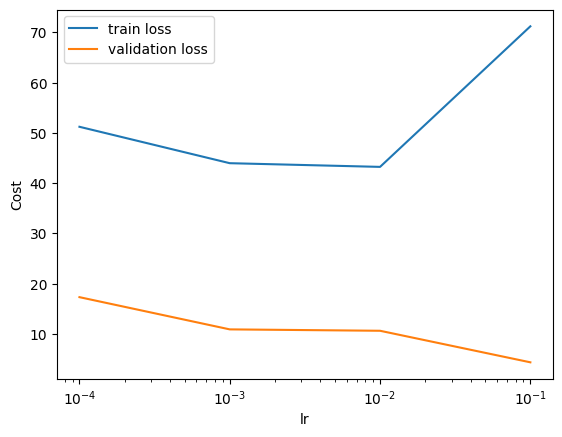

In [10]:
# Plot the training loss and validation loss

plt.semilogx(np.array(lr), train_error.numpy(),label='train loss')
plt.semilogx(np.array(lr), validation_error.numpy(),label='validation loss')
plt.ylabel('Cost')
plt.xlabel('lr')
plt.legend()

0 [[2.3177605]
 [2.2545087]
 [2.191257 ]]
1 [[5.62292  ]
 [5.5046344]
 [5.386348 ]]
2 [[6.5729437]
 [6.4398127]
 [6.306681 ]]
3 [[13.947662 ]
 [13.5304365]
 [13.113211 ]]


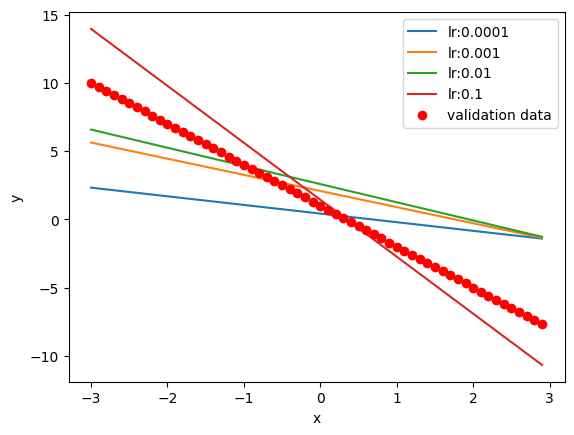

In [11]:
# Plot the predictions
i = 0
for model, lr in zip (MODELS,lr):
    yhat = model(val_data.x)
    plt.plot(val_data.x.numpy(), yhat.detach().numpy(), label='lr:' + str(lr))
    print(i,yhat.detach().numpy()[0:3])
    i+=1

plt.plot(val_data.x.numpy(),val_data.f.numpy(),'or',label='validation data')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()